# Proyecto AFORE, 02: comisiones

Quiero saber cuatro cosas: si el `monto` del archivo ya viene después de comisiones (si es así no hay que restarlas otra vez), cuánto cobran hoy las AFOREs, qué pesa más al elegir entre comisión y rendimiento, y cuánto se lleva la comisión de un ahorro de muchos años.

Las comisiones de este notebook las capturé a mano desde notas de prensa que citan a CONSAR y desde documentos de CONSAR y del CEFP, no desde un archivo oficial. Hay que revisarlas en gob.mx/consar antes de publicarlas.

In [1]:
import sys, os
sys.path.append("../src")
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from limpieza import (cargar_y_limpiar, cargar_inpc, agregar_real, inflacion_anualizada,
                      AFORES, PLAZOS, MESES_PLAZO)

sns.set_theme(style="whitegrid")
pd.set_option("display.width", 170)
pd.set_option("display.max_columns", 30)
os.makedirs("../images/02", exist_ok=True)

DATA_AFORE = "../data/10_rendimientos_precio_bolsa.csv"
DATA_INPC = "../data/inpc_mensual.csv"

def guardar(nombre):
    plt.savefig(f"../images/02/{nombre}.png", dpi=150, bbox_inches="tight")

df, gen, sistema = cargar_y_limpiar(DATA_AFORE)
print("filas:", len(df), "| gen:", len(gen), "| sistema:", len(sistema))

filas: 38179 | gen: 23360 | sistema: 2628


## 1. Si el monto ya incluye la comisión

El archivo se llama rendimientos a precio de bolsa. CONSAR publica dos tipos de rendimiento: a precios de gestión, que es lo que rinde el portafolio antes de comisiones, y a precios de bolsa, que es el que recibe el trabajador con la comisión ya descontada. Una nota de InverCap en El Financiero (junio de 2026) que cita cifras de CONSAR lo dice así: los rendimientos con precios de bolsa ya incluyen el cobro de la comisión.

Entonces trabajo con la idea de que el `monto` ya es neto de comisión y no se resta otra vez. Está bien respaldado pero viene de una fuente secundaria, así que falta confirmarlo en el diccionario de datos de CONSAR.

## 2. Comisiones hoy y cómo han cambiado

Datos sueltos que encontré, con su fuente:

- 2008: de 1.0% (la más barata) a 3.3% (la más cara), según el CEFP.
- 2014: promedio simple del sistema de 1.19%, según CONSAR citada por El Financiero.
- 2019: diferencia de 0.22 puntos entre la más cara y la más barata, según el CEFP.
- 2022: 0.57% para ocho AFOREs y 0.53% para PensionISSSTE, según el informe de labores 2022 de CONSAR.
- 2025: promedio del sistema de 0.547%, según CONSAR citada por El Universal.
- 2026: 0.54% en nueve AFOREs y 0.52% en PensionISSSTE, según notas de prensa que citan a CONSAR.

La comisión se cobra sobre el saldo acumulado, no sobre lo que se aporta cada año.

In [2]:
# comisiones anuales de 2026 (% sobre el saldo). Revisar en gob.mx/consar
COMISION_2026 = {a: 0.54 for a in AFORES}
COMISION_2026["pensionissste"] = 0.52

com = pd.Series(COMISION_2026, name="comision_2026_%").sort_values()
spread_comision = com.max() - com.min()
print(com.to_string())
print(f"\ndiferencia entre la más cara y la más barata: {spread_comision:.2f} puntos")

pensionissste    0.52
azteca           0.54
coppel           0.54
banamex          0.54
inbursa          0.54
invercap         0.54
principal        0.54
profuturo        0.54
sura             0.54
xxi banorte      0.54

diferencia entre la más cara y la más barata: 0.02 puntos


## 3. Comisión o rendimiento
Compara, en cada generación, la diferencia entre la mejor y la peor AFORE a 5 años (último mes) contra la diferencia entre sus comisiones.

In [3]:
g5 = gen[gen["plazo"] == "5 años"].copy()
ultima = g5["fecha"].max()
g5 = g5[g5["fecha"] == ultima]            # solo los fondos con dato en el último mes

tabla = g5.groupby("fondo")["monto"].agg(mejor="max", peor="min")
tabla["diferencia_rendimiento_pp"] = tabla["mejor"] - tabla["peor"]
tabla["diferencia_comision_pp"] = spread_comision
tabla["veces_mas_grande"] = tabla["diferencia_rendimiento_pp"] / tabla["diferencia_comision_pp"]
print(f"corte: {ultima:%b %Y}, rendimiento a 5 años (anualizado)")
display(tabla.round(2))

corte: Dec 2025, rendimiento a 5 años (anualizado)


,mejor,peor,diferencia_rendimiento_pp,diferencia_comision_pp,veces_mas_grande
fondo,,,,,
60-64,7.54,5.41,2.12,0.02,106.18
65-69,7.65,5.42,2.23,0.02,111.65
70-74,7.87,5.49,2.38,0.02,118.75
75-79,8.11,5.71,2.39,0.02,119.74
80-84,8.16,5.90,2.26,0.02,113.11
85-89,8.22,5.91,2.31,0.02,115.44
90-94,8.40,6.00,2.39,0.02,119.73
95-99,8.44,6.07,2.37,0.02,118.56


La comparación es gruesa, porque el rendimiento a 5 años ya incluye comisiones de años anteriores y las de 2021 a 2025 fueron un poco distintas a las de 2026. Pero el orden de magnitud sí se nota: la diferencia de rendimiento entre AFOREs es decenas de veces mayor que la diferencia de comisión.

In [4]:
# qué parte del rendimiento bruto se va en comisión (aproximación con la comisión de hoy)
COM_PROM = 0.54
g90 = g5[g5["fondo"] == "90-94"].set_index("afore")["monto"].rename("neto_5a")
aprox = g90.to_frame()
aprox["bruto_aprox_5a"] = aprox["neto_5a"] + COM_PROM
aprox["comision_como_%_del_bruto"] = COM_PROM / aprox["bruto_aprox_5a"] * 100
display(aprox.sort_values("neto_5a", ascending=False).round(2))
print("es una aproximación: le sumo la comisión de hoy a un rendimiento que cubre 2021 a 2025")

,neto_5a,bruto_aprox_5a,comision_como_%_del_bruto
afore,,,
inbursa,8.40,8.94,6.04
profuturo,8.13,8.67,6.23
xxi banorte,7.88,8.42,6.41
invercap,7.68,8.22,6.57
sura,7.68,8.22,6.57
pensionissste,7.19,7.73,6.98
banamex,6.87,7.41,7.29
principal,6.81,7.35,7.34
azteca,6.32,6.86,7.87


es una aproximación: le sumo la comisión de hoy a un rendimiento que cubre 2021 a 2025


## 4. Cuánto se lleva la comisión en 30 años
Modelo sencillo: aportación anual fija al final de cada año, rendimiento bruto constante, y la comisión se resta al rendimiento. Los supuestos se pueden cambiar y es una ilustración, no una predicción.

,Sin comisión,Hoy (0.54%),"% menos, Hoy (0.54%)",Tope 2022 (0.57%),"% menos, Tope 2022 (0.57%)",Promedio 2014 (1.19%),"% menos, Promedio 2014 (1.19%)"
años,,,,,,,
10,276329.0,269380.5,2.5,269000.3,2.7,261275.5,5.4
20,819909.8,773148.8,5.7,770641.7,6.0,720860.4,12.1
30,1889215.7,1715245.4,9.2,1706120.5,9.7,1529272.8,19.1
40,3992702.2,3477059.3,12.9,3450635.1,13.6,2951274.4,26.1


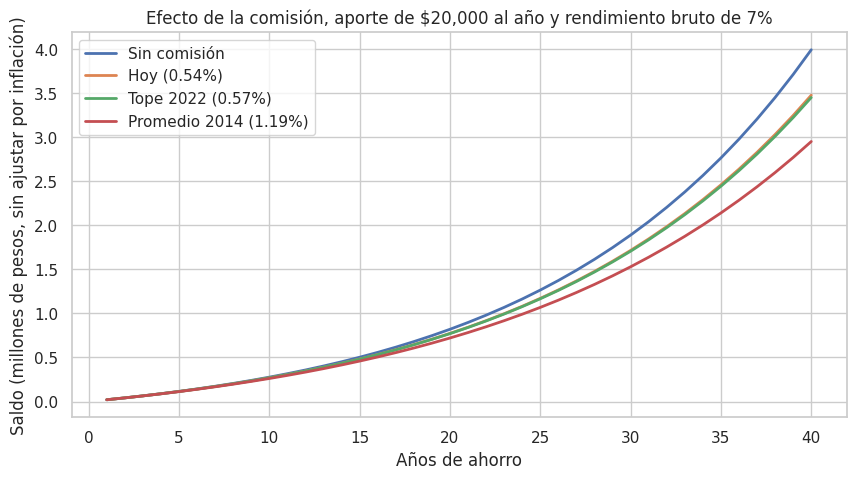

In [5]:
def saldo_final(aporte_anual, anios, r_bruto, comision):
    # saldo al final de `anios` con aportación anual fija y rendimiento neto constante
    r = r_bruto - comision
    saldo = 0.0
    for _ in range(anios):
        saldo = saldo * (1 + r) + aporte_anual
    return saldo

APORTE = 20_000      # pesos al año (supuesto)
R_BRUTO = 0.07       # rendimiento bruto anual (supuesto)
ESCENARIOS = {"Sin comisión": 0.0, "Hoy (0.54%)": 0.0054, "Tope 2022 (0.57%)": 0.0057, "Promedio 2014 (1.19%)": 0.0119}

filas = []
for anios in [10, 20, 30, 40]:
    base = saldo_final(APORTE, anios, R_BRUTO, 0.0)
    fila = {"años": anios}
    for nombre, c in ESCENARIOS.items():
        s = saldo_final(APORTE, anios, R_BRUTO, c)
        fila[nombre] = s
        if c > 0:
            fila[f"% menos, {nombre}"] = (1 - s / base) * 100
    filas.append(fila)
resultado = pd.DataFrame(filas).set_index("años")
display(resultado.round(1))

fig, ax = plt.subplots(figsize=(10, 5))
anios = np.arange(1, 41)
for nombre, c in ESCENARIOS.items():
    ax.plot(anios, [saldo_final(APORTE, a, R_BRUTO, c) / 1e6 for a in anios], label=nombre, lw=2)
ax.set_xlabel("Años de ahorro")
ax.set_ylabel("Saldo (millones de pesos, sin ajustar por inflación)")
ax.set_title(f"Efecto de la comisión, aporte de ${APORTE:,} al año y rendimiento bruto de {R_BRUTO:.0%}")
ax.legend()
guardar("01_efecto_comision")
plt.show()

La comisión parece chica pero se cobra cada año sobre todo el saldo, así que se acumula. Por eso CONSAR la fue bajando, y por eso importa aunque hoy todas cobren casi lo mismo.

## Qué encontré

El `monto` ya viene neto de comisión (con la reserva de que la fuente es secundaria), así que no se resta otra vez.

Hoy la comisión casi no distingue a las AFOREs: 0.54% en nueve de ellas y 0.52% en PensionISSSTE, una diferencia de 0.02 puntos. El rendimiento sí las distingue. A 5 años la diferencia entre la mejor y la peor va de 2.1 a 2.4 puntos según la generación, unas 106 a 120 veces la diferencia de comisión. Es una comparación gruesa por lo que expliqué arriba.

Aun así la comisión pesa en el largo plazo. Con un rendimiento bruto de 7% y aporte anual fijo, una comisión de 0.54% deja 9.2% menos de saldo a 30 años (12.9% a 40 años). Con la comisión promedio de 2014 (1.19%) serían 19.1% y 26.1% menos. Para las AFOREs de la SB 90-94, la comisión se lleva entre 6% (Inbursa) y 8.3% (Coppel) del rendimiento bruto aproximado, usando la comisión de hoy.

Para el proyecto esto quiere decir que elegir AFORE por comisión ya no tiene mucho sentido porque están casi empatadas, y lo que hay que comparar es el rendimiento neto, que ya la incluye.

## Pendiente
- Confirmar en el diccionario de datos de CONSAR que el precio de bolsa incluye la comisión.
- Bajar las comisiones por AFORE y por año (2019 a 2026) del portal de CONSAR para calcular el rendimiento bruto exacto.
- Comparar con el Indicador de Rendimiento Neto (IRN) oficial de CONSAR.